In [14]:
'''Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. 
Perform following tasks: 
1.  Pre-process the dataset. 
2.  Identify outliers. 
3.  Check the correlation. 
4.  Implement linear regression and random forest regression models. 
5.  Evaluate the models and compare their respective scores like R2, RMSE, etc. 
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset'''

'Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. \nPerform following tasks: \n1.  Pre-process the dataset. \n2.  Identify outliers. \n3.  Check the correlation. \n4.  Implement linear regression and random forest regression models. \n5.  Evaluate the models and compare their respective scores like R2, RMSE, etc. \nDataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset'

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [16]:
# 1. Load dataset
df = pd.read_csv("uber.csv")

print("Dataset:")
print(df.head())

Dataset:
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3

In [17]:
# 2. Preprocess data
df = df.dropna().copy()

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce"
)
df = df.dropna(subset=["pickup_datetime"])

# Remove invalid values
df = df[
    (df["fare_amount"] > 0) &
    (df["fare_amount"] < 100) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72))
].copy()

In [18]:
# 3. Calculate distance using Haversine formula
def calculate_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = calculate_distance(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Extract time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month

Number of outliers: 16625
Lower bound: -3.75, Upper bound: 22.25


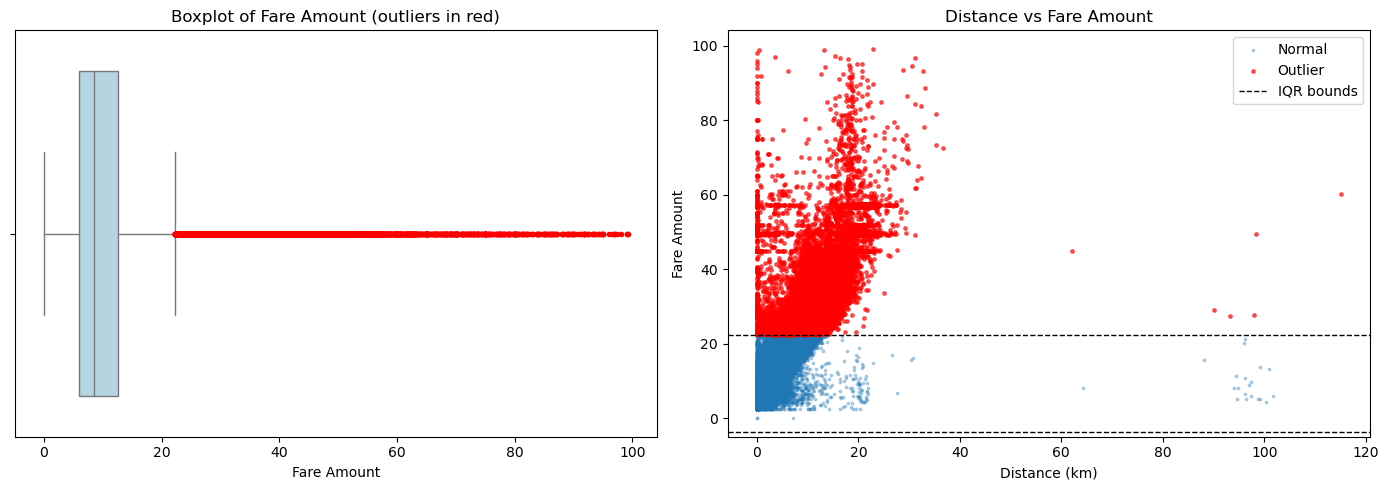

In [19]:
# 4. Identify outliers using IQR and plot them
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

is_outlier = (df["fare_amount"] < lower) | (df["fare_amount"] > upper)
outliers = df[is_outlier]

print("Number of outliers:", len(outliers))
print(f"Lower bound: {lower:.2f}, Upper bound: {upper:.2f}")

# Plot outliers (before removal)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot: points beyond the whiskers are the outliers
sns.boxplot(
    x=df["fare_amount"], ax=axes[0], color="lightblue",
    flierprops={"markerfacecolor": "red", "markeredgecolor": "red", "markersize": 3}
)
axes[0].set_title("Boxplot of Fare Amount (outliers in red)")
axes[0].set_xlabel("Fare Amount")

# Scatter: distance vs fare, outliers highlighted
axes[1].scatter(
    df.loc[~is_outlier, "distance_km"], df.loc[~is_outlier, "fare_amount"],
    s=3, alpha=0.3, label="Normal"
)
axes[1].scatter(
    df.loc[is_outlier, "distance_km"], df.loc[is_outlier, "fare_amount"],
    s=6, alpha=0.6, color="red", label="Outlier"
)
axes[1].axhline(upper, color="black", linestyle="--", linewidth=1, label="IQR bounds")
axes[1].axhline(lower, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Distance vs Fare Amount")
axes[1].set_xlabel("Distance (km)")
axes[1].set_ylabel("Fare Amount")
axes[1].legend()

plt.tight_layout()
plt.show()

# Remove outliers
df = df[
    df["fare_amount"].between(lower, upper) &
    (df["distance_km"] <= 50)
].copy()

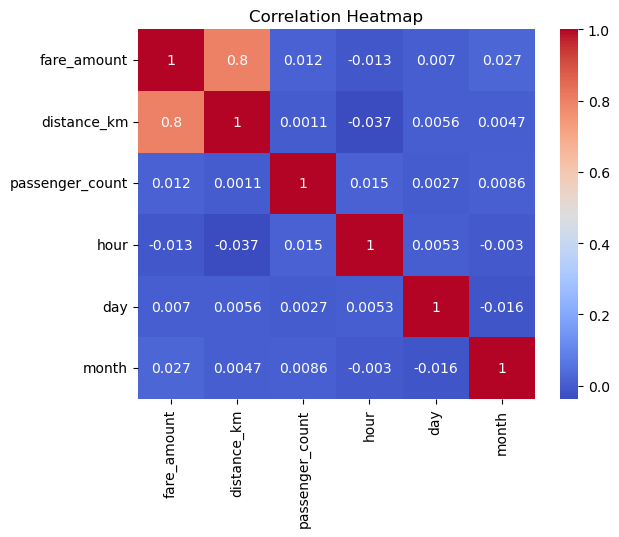

In [20]:
# 5. Check correlation
features = [
    "fare_amount", "distance_km", "passenger_count",
    "hour", "day", "month"
]

correlation = df[features].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [21]:
# 6. Select features and target
X = df[
    [
        "distance_km",
        "passenger_count",
        "hour",
        "day",
        "month",
        "pickup_latitude",
        "pickup_longitude",
        "dropoff_latitude",
        "dropoff_longitude"
    ]
]

y = df["fare_amount"]

# Use a sample to reduce training time
X_sample, _, y_sample, _ = train_test_split(
    X, y, train_size=min(50000, len(X)),
    random_state=42
) if len(X) > 50000 else (X, None, y, None)

In [22]:
# 7. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.2,
    random_state=42
)

In [23]:
# 8. Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

In [24]:
# 9. Random Forest Regression
rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

In [25]:
# 10. Evaluate models
def evaluate(name, actual, predicted):
    print("\n", name)
    print("MAE:", mean_absolute_error(actual, predicted))
    print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))
    print("R2 Score:", r2_score(actual, predicted))

evaluate("Linear Regression", y_test, lr_pred)
evaluate("Random Forest", y_test, rf_pred)

# 11. Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Linear Regression": lr_pred,
    "Random Forest": rf_pred
})

print("\nPrediction Comparison:")
print(comparison.head())


 Linear Regression
MAE: 1.7041662857841096
RMSE: 2.4719813444526806
R2 Score: 0.6351668500458154

 Random Forest
MAE: 1.5102683434618929
RMSE: 2.130342867210447
R2 Score: 0.729041407342375

Prediction Comparison:
   Actual  Linear Regression  Random Forest
0     9.3           8.234402       8.778088
1     4.9           6.958121       7.116144
2    11.3          12.503683      12.872120
3    12.5           8.338484       8.119676
4     5.7           8.465847       8.993488
